# Task 4: Regularization study

**Objective:** increase validation accuracy (if possible) with regularization techniques
(batch normalization, dropout, L2 weight decay) and report how each one affects validation accuracy.

Adam Oakes

**Setup: Task 3's best pipeline is the new baseline**
* Same CNN as the Task 2 best model (5 conv blocks, 32→512 filters, GAP, sigmoid), with
  **horizontal-flip augmentation**, the best pipeline from Task 3 (0.9507 validation accuracy).
  Every regularizer below is added on top of that pipeline.
* Same optimizer (Adam) and batch size (64). Each model trains for up to **20 epochs**; early
  stopping ends a run after 3 epochs without a new best validation accuracy and restores the
  best epoch's weights. Task 3 showed the model only starts to overfit after about 10 epochs,
  and regularization only has something to fix once it does.
* Every configuration trains a **fresh model from the same random seed**, so the only thing
  that changes between rows of the results table is the regularization.
* The baseline (flip, no regularization) is trained twice with two different seeds. The gap
  between those two runs is the **noise floor**.
* Images load at their native 32×32 and are cached in memory; the flip and the 32→180 upsample
  happen inside the model on the GPU.

**The three techniques, and what each one actually does**
* **Dropout** randomly zeroes a fraction of activations at every training step. No single unit
  can be relied on, so the network has to spread information out. It is off at inference.
  It is tested in two places: on the 512 pooled features right before the classifier
  ("head"), and after every conv block ("conv").
* **L2 regularization** adds λ·Σw² to the loss, which pulls every weight toward zero unless
  the data keeps pushing it away. It is applied to every conv and dense kernel.
* **Batch normalization** re-centers and re-scales each channel's activations using the
  statistics of the current batch. It is mainly an optimization aid that lets training move
  faster and more stably. The regularizing effect is a side effect: each image's output depends
  slightly on which other images share its batch, which adds noise.

# Library imports and configuration

In [3]:
import os, json, time
from pathlib import Path

import keras
from keras import layers, regularizers
from keras.utils import image_dataset_from_directory
import tensorflow as tf
# Let TensorFlow take GPU memory as it needs it instead of grabbing it all up front
for _gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(_gpu, True)
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use("default")   # white background + dark text, regardless of the notebook theme

TASK = "task_4"
DATA_DIR = Path(os.environ.get("DATA_DIR", "../../data"))
EPOCHS = int(os.environ.get("EPOCHS", 20))         # upper limit; early stopping usually ends runs sooner
PATIENCE = 3                                       # same early-stopping rule as Task 3
BATCH_SIZE = 64
NATIVE_SIZE = (32, 32)    # CIFAKE images are 32x32
MODEL_SIZE = (180, 180)   # same input size the Task 2 architecture was designed for
SEED = 42
SECOND_SEED = 7           # second baseline run -> noise floor

OUT = Path(os.environ.get("OUT_DIR", "../.."))
plots = OUT / "plots" / TASK
results_dir = OUT / "results" / TASK
for d in (plots, results_dir):
    d.mkdir(parents=True, exist_ok=True)
# Baseline pipeline from Task 3. To use a different one, change these two lines.
BASE_PIPELINE = "flip_h"
AUGMENTATION = [lambda: layers.RandomFlip("horizontal")]

# The file names include the pipeline and epoch limit, so results from an older setup are never
# mistaken for finished runs of this one.
RUN_TAG = f"{BASE_PIPELINE}_e{EPOCHS}"
RESULTS_CSV = results_dir / f"regularization_{RUN_TAG}.csv"
HISTORY_JSON = results_dir / f"regularization_{RUN_TAG}_histories.json"
print("GPUs:", tf.config.list_physical_devices("GPU"))
print("results ->", RESULTS_CSV.resolve())

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
results -> /home/adam/projects/Real_vs_Fake_Classifier/notebooks/results/task_4/regularization_flip_h_e20.csv


# Load the data (native 32×32, cached in memory)

In [4]:
def load(split, shuffle):
    return image_dataset_from_directory(
        DATA_DIR / split, image_size=NATIVE_SIZE, batch_size=BATCH_SIZE,
        shuffle=shuffle, seed=SEED,
    )

train_dataset = load("train", shuffle=True)
validation_dataset = load("validation", shuffle=False)
print(train_dataset.class_names)

# ~1 GB of RAM for 80k 32x32 float images; the training set is reshuffled every epoch.
train_ds = (train_dataset.unbatch().cache()
            .shuffle(20_000, seed=SEED, reshuffle_each_iteration=True)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
val_ds = validation_dataset.cache().prefetch(tf.data.AUTOTUNE)

Found 80000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
['FAKE', 'REAL']


# Model: the Task 2 architecture + horizontal flip, with switchable regularization

A configuration is a small dict. Any key that is missing means "off":

| key | meaning |
|---|---|
| `bn` | Conv (no bias) → BatchNorm → ReLU in every conv block |
| `conv_dropout` | `Dropout(p)` after every max-pool |
| `head_dropout` | `Dropout(p)` on the 512 pooled features, right before the classifier |
| `l2` | `L2(λ)` on every conv and dense kernel |

In [5]:
FILTERS = [32, 64, 128, 256, 512]

def build_model(reg, name):
    bn = reg.get("bn", False)
    l2 = reg.get("l2", 0.0)
    kreg = regularizers.L2(l2) if l2 else None
    inputs = keras.Input(shape=NATIVE_SIZE + (3,))
    x = inputs
    for make in AUGMENTATION:                 # Task 3's best pipeline; active only during training
        x = make()(x)
    x = layers.Resizing(*MODEL_SIZE, interpolation="bilinear")(x)   # same 32->180 upsample as Task 2
    x = layers.Rescaling(1.0 / 255)(x)
    for i, f in enumerate(FILTERS):
        if bn:
            # BN has its own shift (beta), so the conv bias is redundant
            x = layers.Conv2D(f, 3, use_bias=False, kernel_regularizer=kreg)(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
        else:
            x = layers.Conv2D(f, 3, activation="relu", kernel_regularizer=kreg)(x)
        if i < len(FILTERS) - 1:              # last block has no pool, same as Task 2
            x = layers.MaxPooling2D(2)(x)
            if reg.get("conv_dropout"):
                x = layers.Dropout(reg["conv_dropout"])(x)
    x = layers.GlobalAveragePooling2D()(x)
    if reg.get("head_dropout"):
        x = layers.Dropout(reg["head_dropout"])(x)
    outputs = layers.Dense(1, activation="sigmoid", kernel_regularizer=kreg)(x)
    model = keras.Model(inputs, outputs, name=name.replace(".", "p").replace("+", "_"))
    model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
    return model

build_model({"bn": True, "head_dropout": 0.5, "l2": 1e-4}, "preview").summary()

Model: "preview"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 178, 178, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 178, 178, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 87, 87, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 87, 87, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 41, 41, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 41, 41, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 18, 18, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 512)      │     1,179,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,572,065 (6.00 MB)

 Trainable params: 1,570,081 (5.99 MB)

 Non-trainable params: 1,984 (7.75 KB)

# Regularization configurations

Each technique is first tested **by itself**, at several strengths. A few hand-picked pairs
come next, followed by an automatically built **best-of** combination at the end.

In [6]:
# name -> (family, reg dict)
CONFIGS = {
    "baseline":                    ("none",         {}),
    f"baseline_seed{SECOND_SEED}": ("none",         {}),

    "batchnorm":                   ("batchnorm",    {"bn": True}),

    "dropout_head_0.25":           ("dropout_head", {"head_dropout": 0.25}),
    "dropout_head_0.5":            ("dropout_head", {"head_dropout": 0.5}),

    "dropout_conv_0.1":            ("dropout_conv", {"conv_dropout": 0.1}),
    "dropout_conv_0.25":           ("dropout_conv", {"conv_dropout": 0.25}),

    "l2_1e-5":                     ("l2",           {"l2": 1e-5}),
    "l2_1e-4":                     ("l2",           {"l2": 1e-4}),
    "l2_1e-3":                     ("l2",           {"l2": 1e-3}),

    "bn+dropout_head_0.5":         ("combo",        {"bn": True, "head_dropout": 0.5}),
    "bn+l2_1e-4":                  ("combo",        {"bn": True, "l2": 1e-4}),
}

def describe(reg):
    if not reg:
        return "-"
    parts = []
    if reg.get("bn"): parts.append("BatchNorm after every conv")
    if reg.get("conv_dropout"): parts.append(f"Dropout({reg['conv_dropout']}) after every pool")
    if reg.get("head_dropout"): parts.append(f"Dropout({reg['head_dropout']}) before Dense")
    if reg.get("l2"): parts.append(f"L2({reg['l2']:g}) on all kernels")
    return "; ".join(parts)

print(len(CONFIGS), "configurations (+1 auto best-of combo)")

12 configurations (+1 auto best-of combo)


# Run the sweep

The results go to a CSV **after every configuration**. If the kernel dies or you stop it,
re-running this cell skips the configurations that already finished. To start over, delete
the CSV named in the output of the configuration cell.

Expect about 35–40 s per epoch on the GPU (BatchNorm is a little slower), and roughly 10–15
epochs per configuration before early stopping, so about 1.5–2 hours for the whole sweep.

**Use accuracy, not loss, to compare rows.** With L2 turned on, Keras adds the penalty λ·Σw² to
both the training loss and the validation loss it reports, so an L2 run's loss is partly measuring
the weights, not the predictions. Accuracy is the one number that means the same thing in every row.

In [7]:
def load_results():
    return pd.read_csv(RESULTS_CSV) if RESULTS_CSV.exists() else pd.DataFrame()

def load_histories():
    return json.loads(HISTORY_JSON.read_text()) if HISTORY_JSON.exists() else {}

def run_config(name, family, reg, seed=SEED):
    done = load_results()
    if len(done) and name in set(done["config"]):
        print(f"skip {name} (already done)")
        return
    keras.backend.clear_session()   # free the previous model's GPU memory before building the next one
    gc.collect()
    keras.utils.set_random_seed(seed)
    model = build_model(reg, name)
    cb = [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=PATIENCE,
                                        mode="max", restore_best_weights=True)]
    t0 = time.time()
    h = model.fit(train_ds, epochs=EPOCHS, validation_data=val_ds, callbacks=cb, verbose=2)
    secs = time.time() - t0
    hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    best = int(np.argmax(hist["val_accuracy"]))
    row = dict(
        config=name, family=family, description=describe(reg), reg=json.dumps(reg), seed=seed,
        params=model.count_params(),
        best_val_acc=hist["val_accuracy"][best], best_epoch=best + 1,
        final_val_acc=hist["val_accuracy"][-1],
        final_train_acc=hist["accuracy"][-1],
        sec_per_epoch=secs / len(hist["accuracy"]),
    )
    pd.concat([done, pd.DataFrame([row])], ignore_index=True).to_csv(RESULTS_CSV, index=False)
    hs = load_histories(); hs[name] = hist
    HISTORY_JSON.write_text(json.dumps(hs))
    print(f"==> {name}: best val_acc {row['best_val_acc']:.4f} (epoch {row['best_epoch']})")

for name, (family, reg) in CONFIGS.items():
    seed = SECOND_SEED if name.startswith("baseline_seed") else SEED
    run_config(name, family, reg, seed=seed)

Epoch 1/20


/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1250/1250 - 47s - 37ms/step - accuracy: 0.7997 - loss: 0.4317 - val_accuracy: 0.8752 - val_loss: 0.3024
Epoch 2/20
1250/1250 - 33s - 27ms/step - accuracy: 0.8880 - loss: 0.2700 - val_accuracy: 0.8939 - val_loss: 0.2615
Epoch 3/20
1250/1250 - 33s - 26ms/step - accuracy: 0.9057 - loss: 0.2322 - val_accuracy: 0.8989 - val_loss: 0.2417
Epoch 4/20
1250/1250 - 33s - 26ms/step - accuracy: 0.9175 - loss: 0.2070 - val_accuracy: 0.9229 - val_loss: 0.1892
Epoch 5/20
1250/1250 - 33s - 26ms/step - accuracy: 0.9262 - loss: 0.1875 - val_accuracy: 0.9094 - val_loss: 0.2182
Epoch 6/20
1250/1250 - 33s - 26ms/step - accuracy: 0.9324 - loss: 0.1747 - val_accuracy: 0.9309 - val_loss: 0.1760
Epoch 7/20
1250/1250 - 33s - 26ms/step - accuracy: 0.9340 - loss: 0.1662 - val_accuracy: 0.9339 - val_loss: 0.1716
Epoch 8/20
1250/1250 - 33s - 26ms/step - accuracy: 0.9408 - loss: 0.1529 - val_accuracy: 0.9372 - val_loss: 0.1667
Epoch 9/20
1250/1250 - 33s - 26ms/step - accuracy: 0.9424 - loss: 0.1474 - val_accuracy: 0.

/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1250/1250 - 37s - 30ms/step - accuracy: 0.7980 - loss: 0.4291 - val_accuracy: 0.8806 - val_loss: 0.2843
Epoch 2/20
1250/1250 - 33s - 27ms/step - accuracy: 0.8897 - loss: 0.2645 - val_accuracy: 0.9025 - val_loss: 0.2374
Epoch 3/20
1250/1250 - 33s - 26ms/step - accuracy: 0.9096 - loss: 0.2241 - val_accuracy: 0.9133 - val_loss: 0.2194
Epoch 4/20
1250/1250 - 33s - 26ms/step - accuracy: 0.9185 - loss: 0.2019 - val_accuracy: 0.9280 - val_loss: 0.1817
Epoch 5/20
1250/1250 - 33s - 27ms/step - accuracy: 0.9268 - loss: 0.1865 - val_accuracy: 0.9284 - val_loss: 0.1776
Epoch 6/20
1250/1250 - 33s - 26ms/step - accuracy: 0.9315 - loss: 0.1742 - val_accuracy: 0.9277 - val_loss: 0.1777
Epoch 7/20
1250/1250 - 33s - 26ms/step - accuracy: 0.9363 - loss: 0.1620 - val_accuracy: 0.9365 - val_loss: 0.1612
Epoch 8/20
1250/1250 - 33s - 27ms/step - accuracy: 0.9404 - loss: 0.1518 - val_accuracy: 0.9402 - val_loss: 0.1527
Epoch 9/20
1250/1250 - 33s - 26ms/step - accuracy: 0.9442 - loss: 0.1444 - val_accuracy: 0.

/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


... (15 outputs left out)

/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1250/1250 - 47s - 38ms/step - accuracy: 0.8737 - loss: 0.3031 - val_accuracy: 0.8784 - val_loss: 0.2946
Epoch 2/20
1250/1250 - 40s - 32ms/step - accuracy: 0.9146 - loss: 0.2167 - val_accuracy: 0.9040 - val_loss: 0.2514
Epoch 3/20
1250/1250 - 40s - 32ms/step - accuracy: 0.9229 - loss: 0.1958 - val_accuracy: 0.8841 - val_loss: 0.2950
Epoch 4/20
1250/1250 - 40s - 32ms/step - accuracy: 0.9304 - loss: 0.1792 - val_accuracy: 0.8705 - val_loss: 0.3347
Epoch 5/20
1250/1250 - 40s - 32ms/step - accuracy: 0.9356 - loss: 0.1673 - val_accuracy: 0.9128 - val_loss: 0.2175
Epoch 6/20
1250/1250 - 40s - 32ms/step - accuracy: 0.9400 - loss: 0.1564 - val_accuracy: 0.8673 - val_loss: 0.3864
Epoch 7/20
1250/1250 - 40s - 32ms/step - accuracy: 0.9429 - loss: 0.1478 - val_accuracy: 0.9369 - val_loss: 0.1638
Epoch 8/20
1250/1250 - 40s - 32ms/step - accuracy: 0.9463 - loss: 0.1402 - val_accuracy: 0.9255 - val_loss: 0.1882
Epoch 9/20
1250/1250 - 40s - 32ms/step - accuracy: 0.9485 - loss: 0.1338 - val_accuracy: 0.

/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1250/1250 - 47s - 37ms/step - accuracy: 0.8813 - loss: 0.3403 - val_accuracy: 0.8733 - val_loss: 0.3419
Epoch 2/20
1250/1250 - 40s - 32ms/step - accuracy: 0.9126 - loss: 0.2633 - val_accuracy: 0.8163 - val_loss: 0.6543
Epoch 3/20
1250/1250 - 40s - 32ms/step - accuracy: 0.9198 - loss: 0.2477 - val_accuracy: 0.9186 - val_loss: 0.2542
Epoch 4/20
1250/1250 - 40s - 32ms/step - accuracy: 0.9248 - loss: 0.2385 - val_accuracy: 0.6554 - val_loss: 0.8706
Epoch 5/20
1250/1250 - 40s - 32ms/step - accuracy: 0.9281 - loss: 0.2302 - val_accuracy: 0.8224 - val_loss: 0.4678
Epoch 6/20
1250/1250 - 40s - 32ms/step - accuracy: 0.9315 - loss: 0.2219 - val_accuracy: 0.9180 - val_loss: 0.2569
==> bn+l2_1e-4: best val_acc 0.9186 (epoch 3)


## Auto "best-of" combination

For every single-technique family, take the best setting **only if** it beat the baseline by
more than the noise floor. Merge those settings into one model and train it.

In [8]:
res = load_results()
base = res.loc[res.config == "baseline", "best_val_acc"].item()
noise = abs(base - res.loc[res.config.str.startswith("baseline_seed"), "best_val_acc"].item())
singles = res[~res.family.isin(["none", "combo"])]
winners = singles.sort_values("best_val_acc", ascending=False).groupby("family").head(1)
winners = winners[winners.best_val_acc - base > noise]
print(f"baseline {base:.4f}, noise floor ±{noise:.4f}")
print("families that beat the baseline by more than the noise floor:", list(winners.config))

if len(winners) >= 2:
    merged = {}
    for r in winners.reg:
        merged.update(json.loads(r))
    CONFIGS["best_of_combo"] = ("combo", merged)
    run_config("best_of_combo", "combo", merged)
else:
    print("Fewer than two families clearly helped, so there is nothing to combine; skipping best-of combo.")

baseline 0.9428, noise floor ±0.0045
families that beat the baseline by more than the noise floor: ['dropout_head_0.5', 'batchnorm', 'dropout_conv_0.1']
Epoch 1/20


/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1250/1250 - 49s - 39ms/step - accuracy: 0.8632 - loss: 0.3212 - val_accuracy: 0.8541 - val_loss: 0.3615
Epoch 2/20
1250/1250 - 40s - 32ms/step - accuracy: 0.9111 - loss: 0.2224 - val_accuracy: 0.8931 - val_loss: 0.2747
Epoch 3/20
1250/1250 - 41s - 32ms/step - accuracy: 0.9236 - loss: 0.1972 - val_accuracy: 0.8945 - val_loss: 0.2565
Epoch 4/20
1250/1250 - 41s - 32ms/step - accuracy: 0.9276 - loss: 0.1839 - val_accuracy: 0.9155 - val_loss: 0.2194
Epoch 5/20
1250/1250 - 40s - 32ms/step - accuracy: 0.9319 - loss: 0.1734 - val_accuracy: 0.9323 - val_loss: 0.1760
Epoch 6/20
1250/1250 - 40s - 32ms/step - accuracy: 0.9366 - loss: 0.1634 - val_accuracy: 0.8714 - val_loss: 0.3100
Epoch 7/20
1250/1250 - 41s - 32ms/step - accuracy: 0.9396 - loss: 0.1550 - val_accuracy: 0.9400 - val_loss: 0.1527
Epoch 8/20
1250/1250 - 40s - 32ms/step - accuracy: 0.9427 - loss: 0.1488 - val_accuracy: 0.9273 - val_loss: 0.1799
Epoch 9/20
1250/1250 - 41s - 32ms/step - accuracy: 0.9441 - loss: 0.1441 - val_accuracy: 0.

# Results table

In [9]:
res = load_results()
base = res.loc[res.config == "baseline", "best_val_acc"].item()
noise = abs(base - res.loc[res.config.str.startswith("baseline_seed"), "best_val_acc"].item())
res["delta_vs_baseline"] = res.best_val_acc - base
res["overfit_gap"] = res.final_train_acc - res.final_val_acc
order = ["none", "batchnorm", "dropout_head", "dropout_conv", "l2", "combo"]
res["family"] = pd.Categorical(res.family, order, ordered=True)
table = res.sort_values(["family", "config"])[
    ["family", "config", "description", "best_val_acc", "delta_vs_baseline",
     "best_epoch", "final_train_acc", "overfit_gap", "params", "sec_per_epoch"]]

def to_markdown(df):
    fmt = {"best_val_acc": "{:.4f}", "delta_vs_baseline": "{:+.4f}", "final_train_acc": "{:.4f}",
           "overfit_gap": "{:+.4f}", "params": "{:,}", "sec_per_epoch": "{:.0f}"}
    cols = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(fmt.get(c, "{}").format(r[c]) for c in cols) + " |")
    return "\n".join(lines)

md_table = to_markdown(table)
(results_dir / f"regularization_{RUN_TAG}.md").write_text(md_table)
from IPython.display import Markdown, display
display(Markdown(md_table))

| family | config | description | best_val_acc | delta_vs_baseline | best_epoch | final_train_acc | overfit_gap | params | sec_per_epoch |
|---|---|---|---|---|---|---|---|---|---|
| none | baseline | - | 0.9428 | +0.0000 | 10 | 0.9545 | +0.0183 | 1,569,089 | 34 |
| none | baseline_seed7 | - | 0.9473 | +0.0045 | 11 | 0.9589 | +0.0273 | 1,569,089 | 33 |
| batchnorm | batchnorm | BatchNorm after every conv | 0.9475 | +0.0047 | 7 | 0.9576 | +0.0466 | 1,572,065 | 41 |
| dropout_head | dropout_head_0.25 | Dropout(0.25) before Dense | 0.9495 | +0.0067 | 15 | 0.9634 | +0.0156 | 1,569,089 | 33 |
| dropout_head | dropout_head_0.5 | Dropout(0.5) before Dense | 0.9505 | +0.0077 | 18 | 0.9643 | +0.0141 | 1,569,089 | 33 |
| dropout_conv | dropout_conv_0.1 | Dropout(0.1) after every pool | 0.9474 | +0.0046 | 19 | 0.9589 | +0.0223 | 1,569,089 | 34 |
| dropout_conv | dropout_conv_0.25 | Dropout(0.25) after every pool | 0.9245 | -0.0183 | 12 | 0.9368 | +0.0226 | 1,569,089 | 34 |
| l2 | l2_1e-3 | L2(0.001) on all kernels | 0.9082 | -0.0346 | 12 | 0.9026 | -0.0005 | 1,569,089 | 33 |
| l2 | l2_1e-4 | L2(0.0001) on all kernels | 0.9193 | -0.0235 | 5 | 0.9228 | +0.0126 | 1,569,089 | 35 |
| l2 | l2_1e-5 | L2(1e-05) on all kernels | 0.9449 | +0.0021 | 13 | 0.9510 | +0.0154 | 1,569,089 | 34 |
| combo | best_of_combo | BatchNorm after every conv; Dropout(0.1) after every pool; Dropout(0.5) before Dense | 0.9400 | -0.0028 | 7 | 0.9483 | +0.0089 | 1,572,065 | 41 |
| combo | bn+dropout_head_0.5 | BatchNorm after every conv; Dropout(0.5) before Dense | 0.9448 | +0.0020 | 9 | 0.9565 | +0.0755 | 1,572,065 | 41 |
| combo | bn+l2_1e-4 | BatchNorm after every conv; L2(0.0001) on all kernels | 0.9186 | -0.0242 | 3 | 0.9315 | +0.0135 | 1,572,065 | 41 |

# Plots

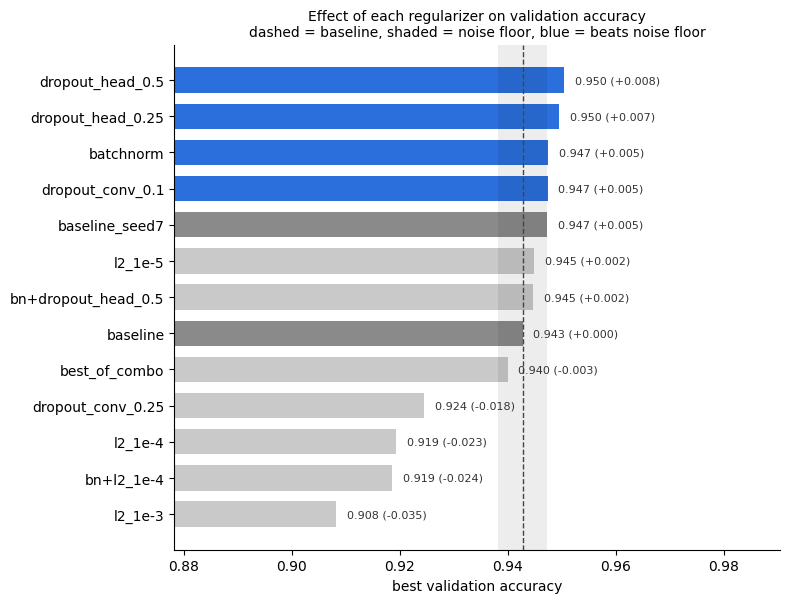

In [10]:
# Validation accuracy per configuration, measured against the baseline and its noise band
t = res.sort_values("best_val_acc")
colors = ["#8a8a8a" if f == "none" else ("#2a6fdb" if d > noise else "#c9c9c9")
          for f, d in zip(t.family, t.delta_vs_baseline)]
fig, ax = plt.subplots(figsize=(8, 0.38 * len(t) + 1.2))
ax.barh(t.config, t.best_val_acc, color=colors, height=0.7)
ax.axvspan(base - noise, base + noise, color="#000", alpha=0.07, lw=0)
ax.axvline(base, color="#444", lw=1, ls="--")
for y, (v, d) in enumerate(zip(t.best_val_acc, t.delta_vs_baseline)):
    ax.text(v + 0.002, y, f"{v:.3f} ({d:+.3f})", va="center", fontsize=8, color="#333")
ax.set_xlim(max(0.5, t.best_val_acc.min() - 0.03), min(1.0, t.best_val_acc.max() + 0.04))
ax.set_xlabel("best validation accuracy")
ax.set_title("Effect of each regularizer on validation accuracy\n"
             "dashed = baseline, shaded = noise floor, blue = beats noise floor", fontsize=10)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout()
fig.savefig(plots / "val_acc_by_regularizer.png", dpi=150)
plt.show()

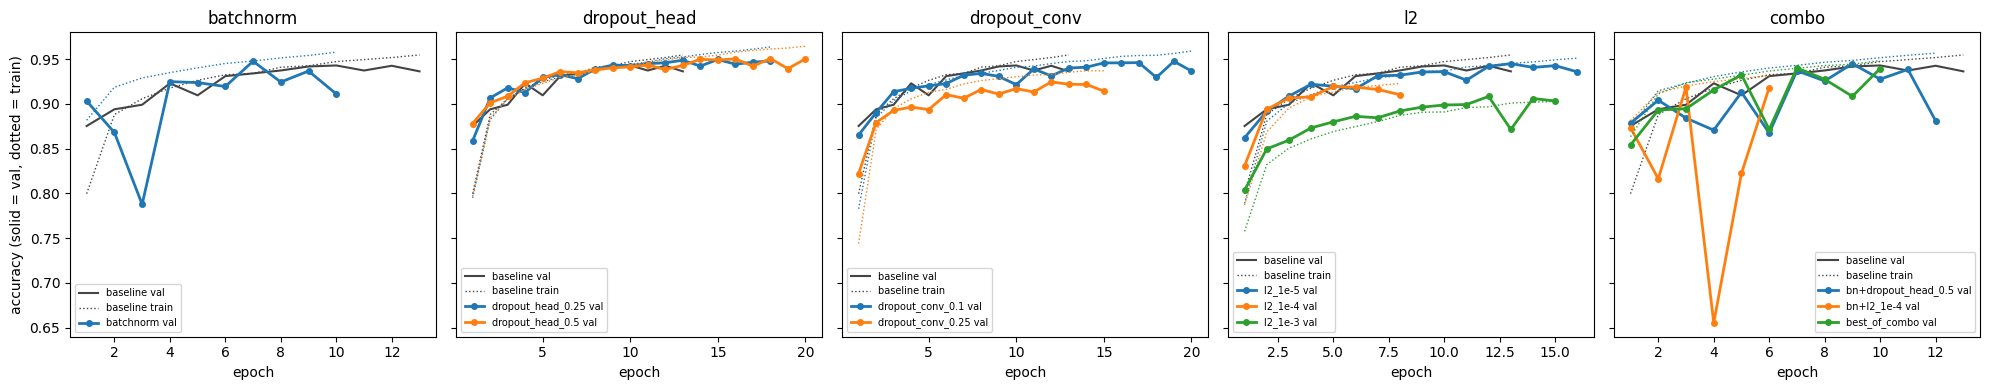

In [11]:
# Train vs validation accuracy, one panel per family: regularization should close the gap between them
hs = load_histories()
fams = [f for f in order if f != "none" and f in set(res.family.astype(str))]
fig, axes = plt.subplots(1, len(fams), figsize=(4 * len(fams), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, fam in zip(axes, fams):
    b = hs["baseline"]
    ep = range(1, len(b["val_accuracy"]) + 1)
    ax.plot(ep, b["val_accuracy"], color="#444", lw=1.5, label="baseline val")
    ax.plot(ep, b["accuracy"], color="#444", lw=1, ls=":", label="baseline train")
    for c in res.loc[res.family == fam, "config"]:
        line, = ax.plot(range(1, len(hs[c]["val_accuracy"]) + 1), hs[c]["val_accuracy"],
                        lw=2, marker="o", ms=4, label=f"{c} val")
        ax.plot(range(1, len(hs[c]["accuracy"]) + 1), hs[c]["accuracy"],
                lw=1, ls=":", color=line.get_color())
    ax.set_title(fam); ax.set_xlabel("epoch"); ax.legend(fontsize=7)
axes[0].set_ylabel("accuracy (solid = val, dotted = train)")
plt.tight_layout()
fig.savefig(plots / "train_val_curves_by_family.png", dpi=150)
plt.show()

# Discussion

*To be written once the run finishes. Compare each row against the flip baseline and its noise
floor, and use `overfit_gap` to check whether a regularizer narrowed the gap between training and
validation accuracy.*

In [12]:
best = res.sort_values("best_val_acc", ascending=False).iloc[0]
print(f"Baseline:            {base:.4f}  (noise floor ±{noise:.4f})")
print(f"Baseline overfit gap: {res.loc[res.config=='baseline','overfit_gap'].item():+.4f}")
print(f"Best configuration:  {best.config}  {best.best_val_acc:.4f}  ({best.best_val_acc - base:+.4f})")
print("Beat the baseline by more than the noise floor:", list(res.loc[res.delta_vs_baseline > noise, "config"]))
print("Hurt by more than the noise floor:", list(res.loc[res.delta_vs_baseline < -noise, "config"]))

Baseline:            0.9428  (noise floor ±0.0045)
Baseline overfit gap: +0.0183
Best configuration:  dropout_head_0.5  0.9505  (+0.0077)
Beat the baseline by more than the noise floor: ['batchnorm', 'dropout_head_0.25', 'dropout_head_0.5', 'dropout_conv_0.1']
Hurt by more than the noise floor: ['dropout_conv_0.25', 'l2_1e-4', 'l2_1e-3', 'bn+l2_1e-4']
